In [1]:
from models.feature_autoencoder import FeatureReconstructionModel
from utils.helpers import set_seed, get_device, load_checkpoint
from visualization import visualize_batch
from utils.data_split import split_data
from torchvision.transforms import v2
from dataset import MVTec2DDataset
import matplotlib.pyplot as plt
from losses import CosineLoss
from engine import train
import torch

W1105 15:19:52.742000 14864 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [2]:
config = {

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # model
    'base_channels': 16,
    'num_epochs': 20,
    'class_name': 'bottle',  # Specify the class name for training and evaluation
}

In [3]:
set_seed(42)
DEVICE = get_device()


Random seed set to 42.
Using device: cuda.


In [4]:
do_split = False  # Set to True if you want to split the dataset into training and validation sets
if do_split:
    # Split a single class
    #split_data(root="./data/MVTec", class_name="bottle", val_ratio=0.15)

    # Or split all classes under data/MVTec at once:
    split_data(root="./data/MVTec", val_ratio=0.15)

In [5]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

transforms = v2.Compose([
    v2.Resize(config['img_size']),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),  # valori in [0, 1]
    #v2.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

target_transforms = v2.Compose([
    v2.Resize(config['img_size'], interpolation=v2.InterpolationMode.NEAREST),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    
])

In [6]:
train_dataset = MVTec2DDataset(
    transforms=transforms,
    class_name=config['class_name'],
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=config['batch_size'],
    shuffle=True,
    num_workers=config['num_workers'],
    pin_memory=True,
)

val_dataset = MVTec2DDataset(
    transforms=transforms,
    split='validation',
    class_name=config['class_name']
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config['num_workers'],
    pin_memory=True,
)

test_dataset = MVTec2DDataset(
    transforms=transforms,
    target_transforms=target_transforms,
    split='test',
    class_name=config['class_name']
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config['num_workers'],
    pin_memory=True,
)

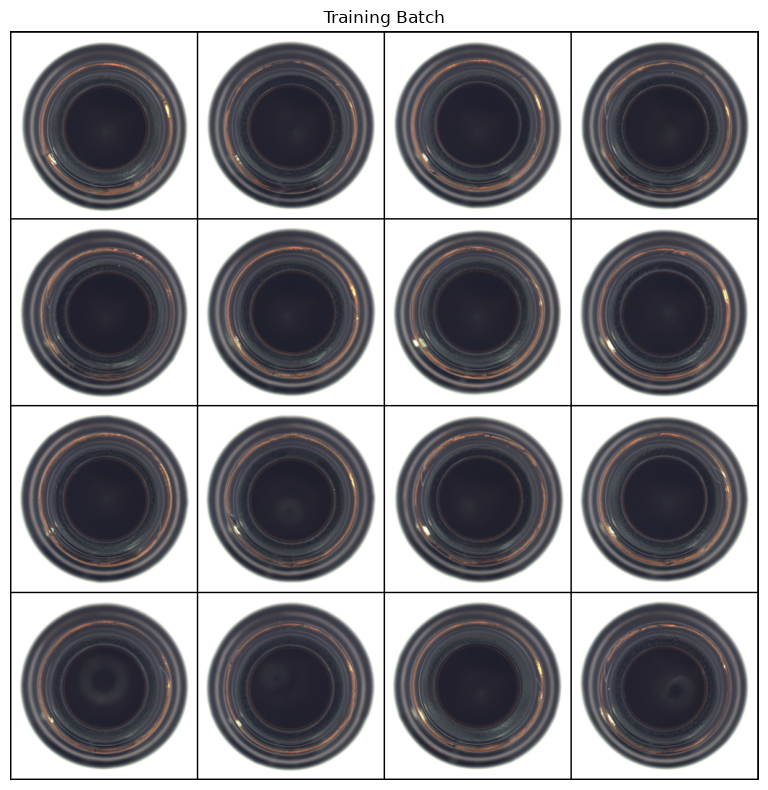

In [7]:
# visualize a batch of images
visualize_batch(train_loader)

In [8]:
# instantiate the model
model = FeatureReconstructionModel(backbone_name='resnet18', feature_layers=['layer3']).to(DEVICE)

In [9]:
# make a single forward pass to check if the model works
# sample_batch = next(iter(train_loader))
# model.train()  # Set the model to training mode
# with torch.no_grad():
#     res = model(sample_batch['image'].to(DEVICE))
#     print(f"Model output: {res}")

Epoch [001/020] | Train Loss: 0.41961 | Val Loss: 0.37153


Epoch [002/020] | Train Loss: 0.27545 | Val Loss: 0.29402


Epoch [003/020] | Train Loss: 0.22815 | Val Loss: 0.23865


Epoch [004/020] | Train Loss: 0.19802 | Val Loss: 0.19856


Epoch [005/020] | Train Loss: 0.17637 | Val Loss: 0.17249


Epoch [006/020] | Train Loss: 0.16081 | Val Loss: 0.15692


... (10 outputs left out)

Epoch [017/020] | Train Loss: 0.09263 | Val Loss: 0.09339


Epoch [018/020] | Train Loss: 0.08944 | Val Loss: 0.09000


Epoch [019/020] | Train Loss: 0.08725 | Val Loss: 0.08822


Epoch [020/020] | Train Loss: 0.08439 | Val Loss: 0.08583


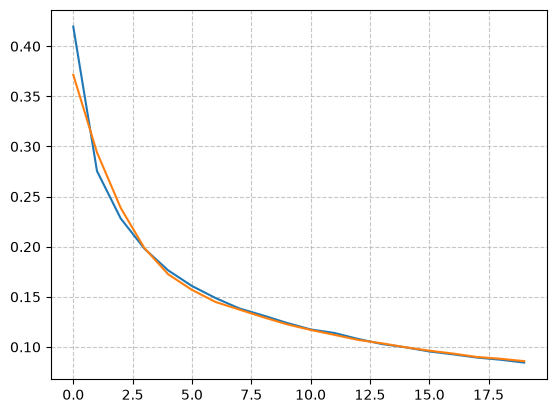

In [10]:
#criterion = nn.MSELoss()

# Invece di criterion = nn.MSELoss()
criterion = CosineLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
do_train = True  # Set to True if you want to train the model
if do_train:
    history = train(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        epochs=config['num_epochs'],
        device=DEVICE,
        save_dir="./experiments/feature_reconstruction/single_layer3_bottle",
    )

    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.grid(linestyle='--', alpha=0.7)

Loaded checkpoint from: experiments\feature_reconstruction\single_layer3_bottle\best_model.pth


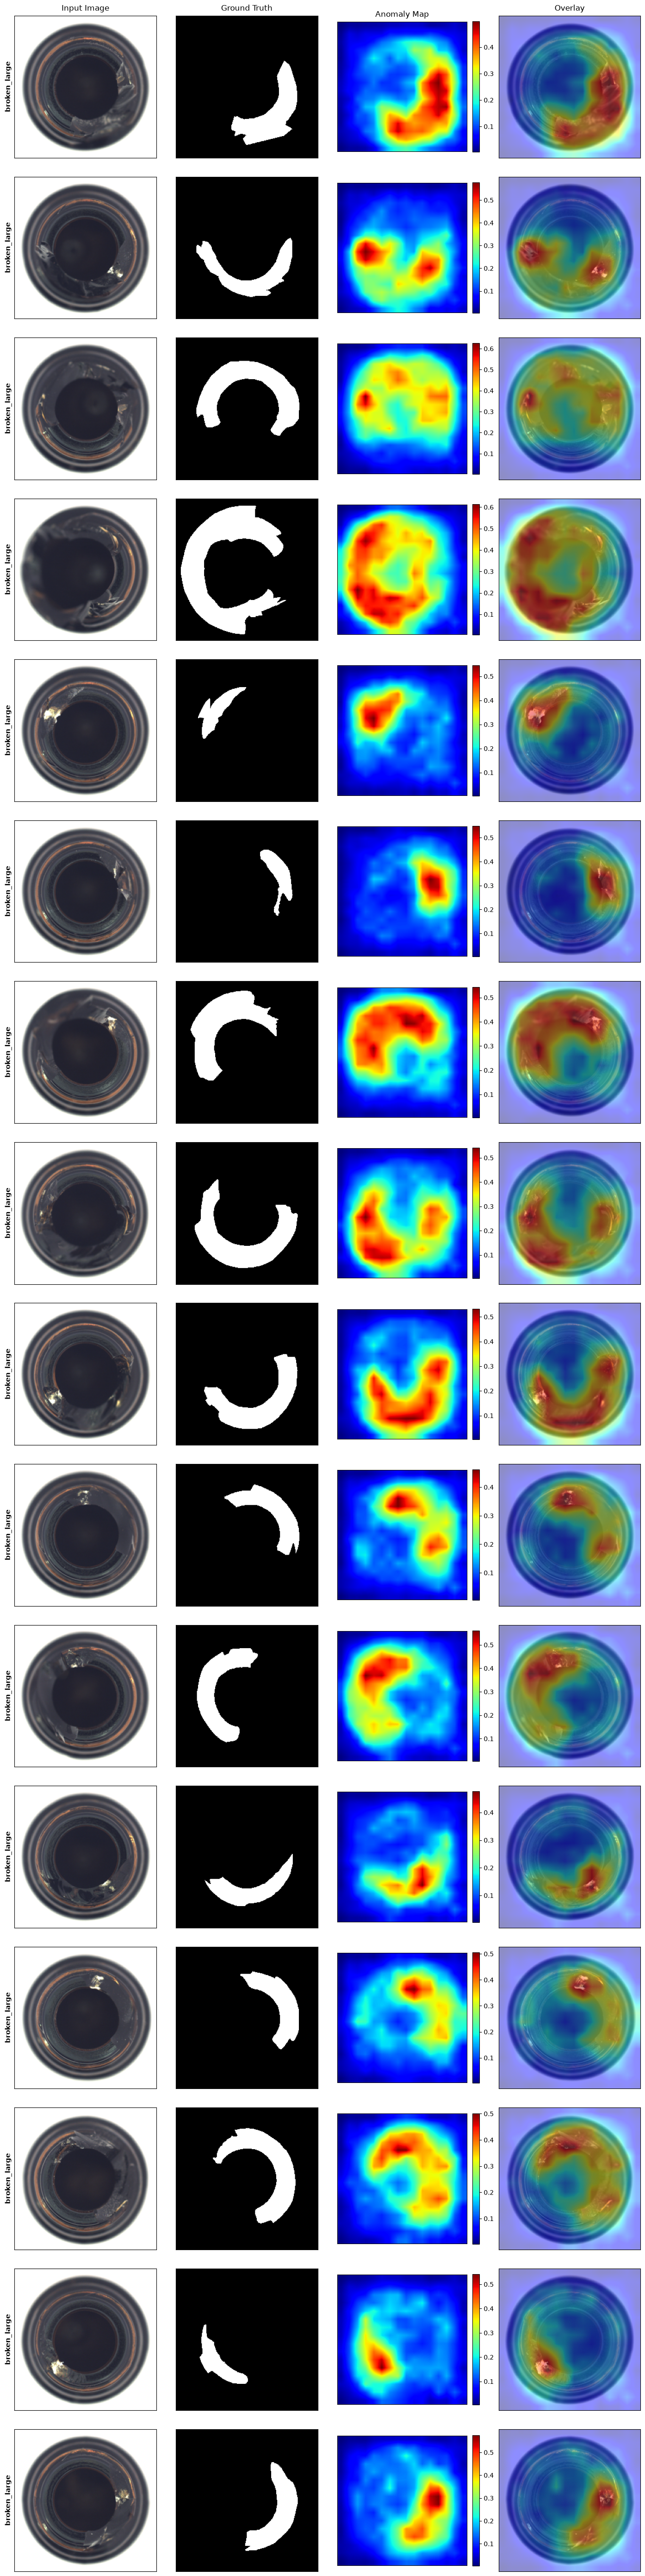

In [11]:
from engine import evaluate
from visualization import visualize_anomalies

# laod the best model checkpoint
checkpoint_path = "./experiments/feature_reconstruction/single_layer3_bottle/best_model.pth"
model = load_checkpoint(model, checkpoint_path, DEVICE)

# 2. Run quantitative evaluation (Image & Pixel AUROC)
metrics = evaluate(model, test_loader, DEVICE)

# 3. Visualize qualitative anomaly heatmaps
visualize_anomalies(model, test_loader, DEVICE, num_samples=16)

In [12]:
for key, value in metrics.items():
    print(f"{key}: {value}")

image_auroc: 0.9920634627342224
pixel_auroc: 0.974624514579773
aupro: 0.8921094536781311
